# 08 — Los picos: cuándo, de qué tipo y qué los rodea

## Qué contesta este cuaderno

El objetivo del proyecto es saber **cuándo sube la tendencia del triage**. Los cuadernos 06 y 07
separaron dos capas: el **nivel**, que mueve la red de salud (Nueva EPS), y los **picos**, que
mueven otras cosas. Este cuaderno mira de frente los picos, con las hipótesis del propietario
preregistradas el 2026-09-29 en `patrones/datos/variables.csv`:

1. **¿Hay un solo tipo de pico?** Días puntuales contra semanas altas sostenidas.
2. **Diciembre** (`diciembre_noches_festivas`): velitas, Navidad, 31 y Año Nuevo. Alcohol, riñas y
   pólvora.
3. **La temporada de fin de año, día por día**, con la Feria y el Carnaval de Riosucio encima.
4. **Las fiestas de los pueblos** (`fiestas_pueblos`): lo que el hospital del pueblo no atiende,
   ¿termina en Manizales?
5. **La mitad de año** (`mitad_de_anio`), con las vacaciones escolares oficiales.

## De dónde salen los datos

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario, por hora, edad y asegurador del SES | `salidas/triage_*.parquet` | base del hospital, agregada (`extraccion/`) |
| Festivos y calendario | `calendarios/calendario_Colombia.csv` | calendario oficial de Colombia |
| Fiestas de 26 municipios de Caldas | `calendarios/fiestas_caldas_2020_2026.csv` | alcaldías, Gobernación, Cultura de Caldas y prensa; una URL por fila |
| Eventos de Manizales (Feria) | `calendarios/eventos_manizales_2020_2026.csv` | calendario manual con fuente |
| Lesiones personales por día (Policía) | `calendarios/seguridad_mindefensa.csv.gz` | MinDefensa, datos.gov.co |
| Lesiones por pólvora (evento 452) y consultas por IRA | `calendarios/vigilancia_sivigila*.csv.gz` | microdatos SIVIGILA, INS |
| Vacaciones escolares de mitad de año | resoluciones de la Secretaría de Educación de Manizales | `calendarios/docs/CONTEXTO_PICOS.md`, §3 |
| Balances oficiales de pólvora, alertas y alumbrado | `calendarios/docs/CONTEXTO_PICOS.md` | DTSC, Gobernación y Alcaldía |

## Un límite que hay que tener presente

El triage cuenta **lo que el hospital recibe**, no lo que la ciudad necesita. En días de
saturación (el SES llegó al 200 % en marzo de 2025 y hubo alerta hospitalaria en julio de 2025),
el conteo puede quedarse **corto** justo cuando la demanda es mayor.


In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from extraccion.entidades import clasificar

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
FIN, INI = "2026-09-20", "2022-03-01"
COVID = ("2020-03-15", "2022-02-28")
dias = pd.date_range("2020-01-01", FIN)
pct = lambda x: (np.exp(x) - 1) * 100

tri = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
tri = tri.set_index("dia")["triages"].reindex(dias).astype(float)
tri["2024-03-21"] = np.nan                          # caida parcial del registro (cuaderno 01)
hor = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
madrugada = hor[hor.hora < 6].groupby("dia")["triages"].sum().reindex(dias).fillna(0)
edad = (pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
          .pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0))
grp = (clasificar(pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet"))
         .pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(dias).fillna(0))
seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
S = pd.DataFrame({"total": tri, "madrugada": madrugada, "0-4": edad["0-4"], "15-44": edad["15-44"],
                  "65+": edad["65-+"], "lesiones_ciudad": seg["lesiones_personales"]}).join(grp)
S.loc[tri.isna(), [c for c in S.columns if c != "lesiones_ciudad"]] = np.nan

calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
fest = calc["es_festivo"].fillna(0).astype(int)
dow = dias.dayofweek
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fiestas = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv")
vig = pd.concat([pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
                 if "instituciones" not in p.name], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
print(f"{int(tri.sum()):,} triages; {len(fiestas)} fiestas de {fiestas.municipio.nunique()} municipios")


433,258 triages; 177 fiestas de 26 municipios


In [2]:
# ---------- dos controles, a proposito distintos
# (A) solo dia de la semana, festivo y nivel del anio. NO lleva temporada navidena ni fin de anio:
#     si los llevara, se comeria justo el efecto de diciembre que se quiere medir.
# (B) el control completo de los cuadernos 06-07 (mas vacaciones, quincena, Semana Santa, navidad...).
anio = pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)
dsem = pd.get_dummies(pd.Index(dow), prefix="d", drop_first=True).set_index(dias).astype(float)
CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad", "es_temporada_fin_anio",
       "es_regreso_colegio"]
ZA = pd.concat([dsem, fest.rename("festivo").astype(float), anio], axis=1); ZA.insert(0, "c", 1.0)
ZB = pd.concat([dsem, calc[CAL].apply(pd.to_numeric, errors="coerce").fillna(0), anio], axis=1); ZB.insert(0, "c", 1.0)
fuera = ~dias.to_series().between(*COVID).values

def residuo(y, Z):
    ly = np.log(y + 0.5); ok = fuera & y.notna().values
    b, *_ = np.linalg.lstsq(Z.values[ok], ly.values[ok], rcond=None)
    return (ly - Z.values @ b).where(y.notna())

RA = pd.DataFrame({c: residuo(S[c], ZA) for c in S.columns}, index=dias)
RB = pd.DataFrame({c: residuo(S[c], ZB) for c in ["total"]}, index=dias)
V = RB.loc[INI:FIN]
local = V.total - V.total.rolling(29, center=True, min_periods=20).median()
sd = local.std()
print(f"sd del residuo diario sobre el nivel local: {sd:.3f}")


sd del residuo diario sobre el nivel local: 0.099


---
# 1. Dos tipos de pico

**Días puntuales**: más de 1,5 desviaciones por encima del nivel local (la mediana de los 14 días antes y después). **Semanas altas sostenidas**: semanas cuya media supera en una desviación el nivel del año, **sin** quitar la estacionalidad. La primera es una noche; la segunda, una temporada.

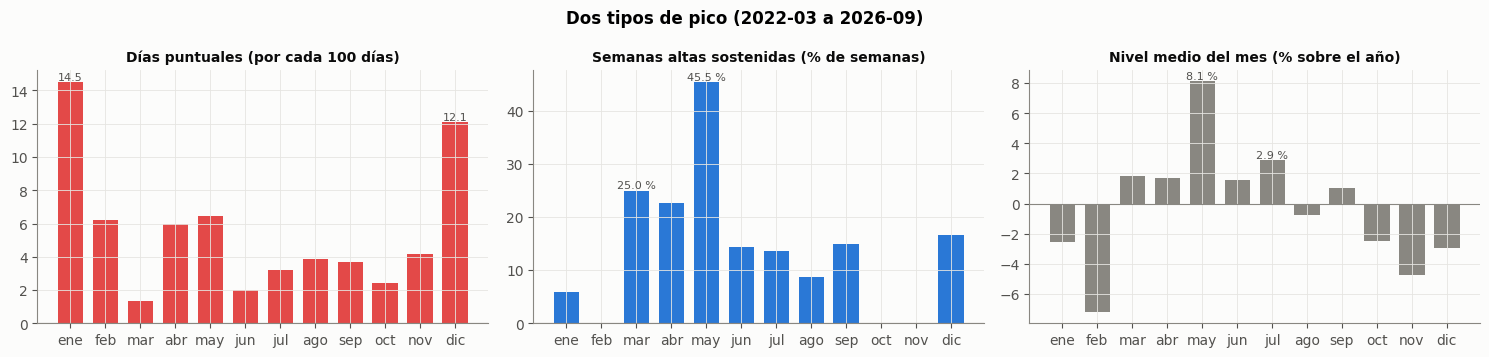

,días puntuales /100 días,semanas altas %,nivel del mes %
ene,14.5,6.0,-2.6
feb,6.2,0.0,-7.2
mar,1.4,25.0,1.8
abr,6.0,23.0,1.7
may,6.5,45.0,8.1
jun,2.0,14.0,1.6
jul,3.2,14.0,2.9
ago,3.9,9.0,-0.8
sep,3.7,15.0,1.0
oct,2.4,0.0,-2.5


In [3]:
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
p15 = local > 1.5 * sd
dias_mes = local.notna().groupby(local.index.month).sum()
puntuales = 100 * p15.groupby(p15.index.month).sum() / dias_mes
w = V.total.resample("W-SAT").mean()[V.total.resample("W-SAT").count() == 7]
alta = w > w.std()
sostenidas = 100 * alta.groupby(alta.index.month).mean()
nivel = pct(V.total.groupby(V.index.month).mean())
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, s, t, col, u in [(axes[0], puntuales, "Días puntuales (por cada 100 días)", ROJO, ""),
                         (axes[1], sostenidas, "Semanas altas sostenidas (% de semanas)", AZUL, " %"),
                         (axes[2], nivel, "Nivel medio del mes (% sobre el año)", MUDO, " %")]:
    s = s.reindex(range(1, 13)).fillna(0)
    ax.bar(range(12), s.values, color=col, width=.72)
    ax.set_xticks(range(12), meses); ax.set_title(t, fontsize=10); ax.axhline(0, color=MUDO, lw=.8)
    for i in s.values.argsort()[-2:]:
        ax.text(i, s.values[i], f"{s.values[i]:.1f}{u}", ha="center", va="bottom", fontsize=8, color=TINTA2)
fig.suptitle("Dos tipos de pico (2022-03 a 2026-09)", fontweight="bold"); plt.tight_layout(); plt.show()
tabla1 = pd.DataFrame({"días puntuales /100 días": puntuales.round(1), "semanas altas %": sostenidas.round(0),
                       "nivel del mes %": nivel.round(1)}).reindex(range(1, 13)); tabla1.index = meses
tabla1


## Lectura

**Hay dos tipos de pico, y no se parecen.**

| | Días puntuales (por cada 100 días) | Semanas altas (%) | Nivel del mes |
|---|---|---|---|
| **Enero** | **14,5** | 6 | −2,6 % |
| **Diciembre** | **12,1** | 17 | −2,9 % |
| Marzo-abril | 1,4-6,0 | 23-25 | +1,7 a +1,8 % |
| **Mayo** | 6,5 | **45** | **+8,1 %** |
| Octubre-noviembre | 2,4-4,2 | **0** | −2,5 a −4,7 % |

- **Diciembre y enero** tienen días sueltos muy altos dentro de meses que en conjunto son bajos.
  Son **noches y días concretos**, no temporadas.
- **Marzo-mayo** tiene **semanas enteras altas**. Es una **temporada**.
- **Octubre y noviembre** no tienen ni una semana alta.

Un pico de diciembre y uno de mayo piden variables distintas para anticiparlos:
- el de diciembre, el **calendario festivo** (se sabe con meses de antelación);
- el de mayo, **lo que viene subiendo desde semanas antes**.

**Límite importante de esta figura.** Usa el control completo, que incluye las «vacaciones
escolares» del calendario. Por eso **descuenta** el efecto de las vacaciones de mitad de año, y
junio-julio salen bajos aquí. La sección 5 lo mide sin ese descuento, y la conclusión sobre la
mitad de año cambia.

---
# 2. Diciembre: las noches festivas

Preregistrado (`diciembre_noches_festivas`): las noches de **7 de diciembre (velitas), 24, 25 y 31 de diciembre y 1 de enero**, y el día siguiente a cada una. Comparador: **los demás festivos y domingos del año**, que tampoco son días laborales. Control (A): día de la semana, festivo y año, **sin** temporada navideña, que se comería el efecto. La huella esperada es madrugada, 15-44 y particulares. El contraste externo son las **lesiones personales registradas por la Policía** ese mismo día.

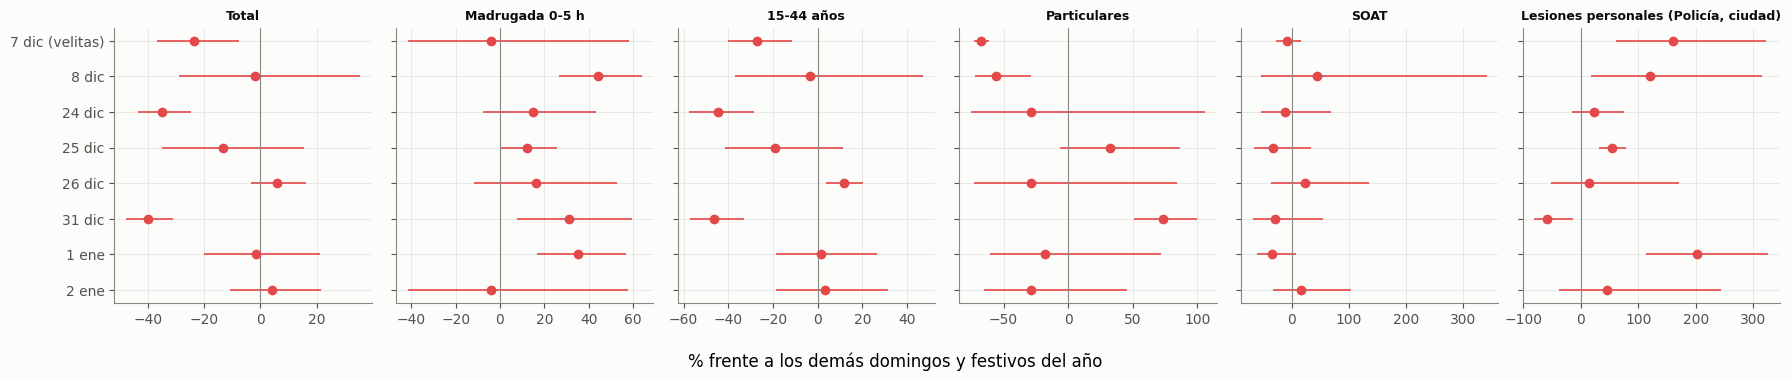

serie,Total,Madrugada 0-5 h,15-44 años,Particulares,SOAT,"Lesiones personales (Policía, ciudad)"
noche,,,,,,
7 dic (velitas),-24.0,-4.0,-27.0,-68.0,-8.0,161.0
8 dic,-2.0,44.0,-4.0,-56.0,44.0,120.0
24 dic,-35.0,15.0,-45.0,-29.0,-13.0,22.0
25 dic,-13.0,12.0,-19.0,32.0,-32.0,54.0
26 dic,6.0,16.0,12.0,-29.0,23.0,14.0
31 dic,-40.0,31.0,-47.0,74.0,-30.0,-59.0
1 ene,-2.0,35.0,2.0,-18.0,-35.0,201.0
2 ene,4.0,-4.0,3.0,-29.0,17.0,46.0


In [4]:
fechas_dic = []
for a in range(2020, 2027):
    for m, d in [(12, 7), (12, 8), (12, 24), (12, 25), (12, 26), (12, 31), (1, 1), (1, 2)]:
        f = pd.Timestamp(a, m, d)
        if f in RA.index and not (pd.Timestamp(COVID[0]) <= f <= pd.Timestamp(COVID[1])): fechas_dic.append(f)
fechas_dic = pd.DatetimeIndex(sorted(set(fechas_dic)))
comparador = RA.index[((dow == 6) | (fest == 1)) & ~RA.index.isin(fechas_dic) & ~RA.index.month.isin([12, 1]) & fuera]
nombres = {(12, 7): "7 dic (velitas)", (12, 8): "8 dic", (12, 24): "24 dic", (12, 25): "25 dic", (12, 26): "26 dic",
           (12, 31): "31 dic", (1, 1): "1 ene", (1, 2): "2 ene"}
cols = {"total": "Total", "madrugada": "Madrugada 0-5 h", "15-44": "15-44 años", "particular": "Particulares",
        "soat_aseguradora": "SOAT", "lesiones_ciudad": "Lesiones personales (Policía, ciudad)"}
filas = []
for c, nom in cols.items():
    base = RA[c].loc[comparador].dropna()
    for (m, d), nd in nombres.items():
        x = RA[c].loc[[f for f in fechas_dic if f.month == m and f.day == d]].dropna()
        if len(x) < 2: continue
        dif = x.mean() - base.mean(); e = 1.96 * np.sqrt(x.var() / len(x) + base.var() / len(base))
        filas.append({"serie": nom, "noche": nd, "efecto %": pct(dif), "bajo": pct(dif - e), "alto": pct(dif + e), "años": len(x)})
T2 = pd.DataFrame(filas)
fig, axes = plt.subplots(1, len(cols), figsize=(18, 3.8), sharey=True)
orden = list(nombres.values())
for ax, (s, g) in zip(axes, T2.groupby("serie", sort=False)):
    g = g.set_index("noche").reindex(orden).dropna()
    y = [orden.index(i) for i in g.index]
    ax.errorbar(g["efecto %"], y, xerr=[g["efecto %"] - g.bajo, g.alto - g["efecto %"]], fmt="o", color=ROJO, ms=6, lw=1.2)
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(s, fontsize=9)
axes[0].set_yticks(range(len(orden)), orden); axes[0].invert_yaxis()
fig.supxlabel("% frente a los demás domingos y festivos del año"); plt.tight_layout(); plt.show()
T2.pivot_table(index="noche", columns="serie", values="efecto %", sort=False).reindex(orden).round(0)


In [5]:
# Polvora: SIVIGILA 452 en Manizales, semanas de diciembre y enero contra el resto
man = vig[vig.ambito.eq("manizales") & vig.evento.eq(452)]
v452 = man[man.variable.eq("casos_ocurrencia")].groupby("fecha_inicio_semana")["valor"].sum()
v452 = v452.loc["2015":]
temporada = v452.index.month.isin([12, 1])
print(f"Lesiones por pólvora en Manizales (SIVIGILA 452, 2015-2025): {int(v452.sum())} casos")
print(f"  en semanas de dic-ene: {int(v452[temporada].sum())} ({100*v452[temporada].sum()/v452.sum():.0f} %)")
print(f"  casos por semana en temporada: {v452[temporada].mean():.2f}; resto del año: {v452[~temporada].mean():.2f}")


Lesiones por pólvora en Manizales (SIVIGILA 452, 2015-2025): 163 casos
  en semanas de dic-ene: 131 (80 %)
  casos por semana en temporada: 1.34; resto del año: 0.07


## Lectura

**Las noches festivas no suben el día: lo mueven a la madrugada y a otra gente.** Todo se compara
con los demás domingos y festivos del año.

| Noche | Total | Madrugada | Particulares | Lesiones (Policía, ciudad) |
|---|---|---|---|---|
| 7 dic (velitas) | **−24 %** | −4 % | −68 % | **+161 %** |
| 8 dic | −2 % | **+44 %** | −56 % | **+120 %** |
| 24 dic | **−35 %** | +15 % | −29 % | +22 % |
| 25 dic | −13 % | +12 % | +32 % | **+54 %** |
| 31 dic | **−40 %** | **+31 %** | **+74 %** | −59 % |
| 1 ene | −2 % | **+35 %** | −18 % | **+201 %** |

1. **En la ciudad, las noches de fiesta son violentas.** Las lesiones personales que registra la
   Policía se multiplican por 2,6 en velitas, por 2,2 el 8 de diciembre y por 3 el 1 de enero. El
   31 aparece bajo porque las riñas de esa noche caen **después de medianoche**, ya el 1 de
   enero. Es lo que describía el propietario: alcohol, riñas y fiesta.
2. **En el SES el día completo baja** en velitas, el 24 y el 31, de un 24 a un 40 % frente a otro
   festivo: la gente está en casa o de fiesta. **Pero la madrugada sube**: +44 % la madrugada
   después de velitas, +31 % el 31 y +35 % el 1 de enero. **Lo que llega es de noche.**
3. **El 31 llegan +74 % de particulares**, gente sin asegurador a mano, que encaja con visitantes
   y con quien no pasa por su EPS en festivo.
4. **La pólvora es real, pero pequeña en el conteo.** El 80 % de los quemados de Manizales del
   SIVIGILA (131 de 163, 2015-2025) cae en diciembre-enero, **1,3 casos por semana en temporada
   contra 0,07 el resto del año**. Frente a ~177 triages diarios, no explica el pico sola.

**Límites.**
- Cada noche tiene 4-5 años de datos, así que los intervalos son anchos. Son significativas
  solo las marcas cuya barra no cruza el cero en la figura.
- La serie de la Policía es de toda la ciudad. No dice cuántos de esos lesionados fueron al SES.

---
# 3. La temporada de fin de año, día por día

Residuo del total (control A) del 1 de diciembre al 31 de enero, un año por línea, con la media en azul. Marcas: 7 de diciembre, 24-25, 31, 1 de enero, Reyes y el inicio de la Feria de cada año.

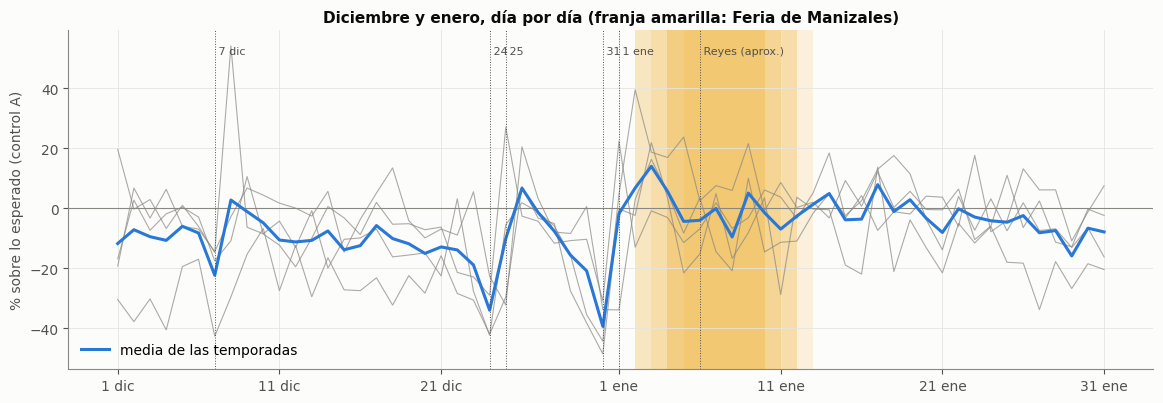

,media %,temporadas
03-Jan,14.0,4
17-Jan,7.8,4
02-Jan,6.7,4
26-Dec,6.7,4
04-Jan,5.6,4
09-Jan,5.0,4
14-Jan,4.9,4
19-Jan,2.8,4
08-Dec,2.7,4
13-Jan,1.2,4


In [6]:
curvas = {}
for a in range(2023, 2027):          # desde dic-2022: la temporada 2021-22 cae en la ventana COVID, fuera del ajuste
    ini = pd.Timestamp(a - 1, 12, 1); fin = pd.Timestamp(a, 1, 31)
    s = RA.total.loc[ini:fin]
    if s.notna().sum() < 40: continue
    s.index = (s.index - ini).days
    curvas[f"{a-1}-{a}"] = pct(s)
Mx = pd.DataFrame(curvas)
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.axhline(0, color=MUDO, lw=.8)
for c in Mx.columns: ax.plot(Mx.index, Mx[c], color=MUDO, lw=.8, alpha=.7)
ax.plot(Mx.index, Mx.mean(axis=1), color=AZUL, lw=2.2, label="media de las temporadas")
marcas = {6: "7 dic", 23: "24", 24: "25", 30: "31", 31: "1 ene", 36: "Reyes (aprox.)"}
for k, t in marcas.items():
    ax.axvline(k, color=TINTA2, lw=.7, ls=":"); ax.text(k, Mx.max().max() * .95, " " + t, fontsize=8, color=TINTA2)
ferias = eventos[eventos.nombre_evento.eq("Feria de Manizales") & eventos.estado.eq("realizado")]
for _, f in ferias.iterrows():
    k = (pd.Timestamp(f.fecha_inicio) - pd.Timestamp(pd.Timestamp(f.fecha_inicio).year - 1, 12, 1)).days
    if 0 <= k <= 61: ax.axvspan(k, k + 8, color=AMARILLO, alpha=.12, lw=0)
ax.set_xticks([0, 10, 20, 31, 41, 51, 61], ["1 dic", "11 dic", "21 dic", "1 ene", "11 ene", "21 ene", "31 ene"])
ax.set_ylabel("% sobre lo esperado (control A)"); ax.legend(loc="lower left")
ax.set_title("Diciembre y enero, día por día (franja amarilla: Feria de Manizales)"); plt.show()
top = pd.DataFrame({"media %": Mx.mean(axis=1).round(1), "temporadas": Mx.notna().sum(axis=1)})
top.index = [(pd.Timestamp(2021, 12, 1) + pd.Timedelta(days=int(i))).strftime("%d-%b") for i in top.index]
top.sort_values("media %", ascending=False).head(10)


## Lectura

**El pico de fin de año llega el día después, no la noche de fiesta.** Los días más altos de
diciembre y enero, en media de las 4 temporadas limpias (dic-2022 a ene-2026):

| Día | Media sobre lo esperado |
|---|---|
| **3 de enero** | **+14,0 %** |
| 17 de enero | +7,8 % |
| 2 de enero | +6,7 % |
| 26 de diciembre | +6,7 % |
| 4 de enero | +5,6 % |
| 9 de enero | +5,0 % |

- La figura lo muestra en forma de **pozo y rebote**. Las noches del 24 y del 31 hunden el
  conteo (−30 a −40 %), y los días siguientes vuelven por encima de lo normal, sobre todo del 2
  al 4 de enero.
- Es la forma que describía el propietario: la fiesta pasa y **la consecuencia llega después**,
  cuando la gente decide consultar o cuando vuelve a haber servicio normal.
- **Del 2 al 4 de enero se juntan tres cosas** que no se pueden separar con 4 temporadas: el día
  después de Año Nuevo, el regreso de las vacaciones y el arranque de la Feria (franja amarilla).
  El cuaderno 07 ya mostró que la Feria sí tiene huella propia (SOAT +37 % frente a +12 % de
  otros regresos).
- El Carnaval de Riosucio (enero de 2023 y 2025) coincide con esas mismas fechas.

**Corrección hecha en este cuaderno.** La primera versión incluía la temporada 2021-2022, que
cae en la ventana COVID que el modelo no ajusta. Con ella, el 8-10 de diciembre salía como el
pico más alto (+11 a +17 %). Sin ella, el 8 de diciembre queda en +2,7 %. **La temporada COVID
fabricaba el pico de velitas.**

---
# 4. Las fiestas de los pueblos

Preregistrado (`fiestas_pueblos`): días de fiesta **realizada** en municipios de Caldas y los 3 días siguientes. Se mira el total y **quién paga**: particulares, ente territorial e IPS remitente, que es la huella de quien llega sin EPS a mano o remitido. Se separa por distancia a Manizales. Control (B) completo. Las fiestas coinciden a menudo con puentes festivos, y el control ya los descuenta.

In [7]:
RBg = pd.DataFrame({c: residuo(S[c], ZB) for c in ["total", "particular", "ente_territorial", "ips_remitente", "15-44", "madrugada"]}, index=dias)
ok = fiestas.estado.isin(["realizado", "virtual"]) & fiestas.fecha_inicio.notna()
F = fiestas[ok].copy(); F["ini"] = pd.to_datetime(F.fecha_inicio); F["fin"] = pd.to_datetime(F.fecha_fin).fillna(F["ini"])
F = F[(F.ini >= pd.Timestamp(INI)) & (F.ini <= pd.Timestamp(FIN))]
filas = []
for nom, sel in [("cerca (< 60 km)", F.distancia_km_manizales < 60), ("lejos (≥ 60 km)", F.distancia_km_manizales >= 60), ("todas", F.index == F.index)]:
    marca = pd.Series(False, index=dias)
    for _, f in F[sel].iterrows(): marca.loc[f.ini: f.fin + pd.Timedelta(days=3)] = True
    marca = marca.loc[INI:FIN]
    for c in RBg.columns:
        y = RBg[c].loc[INI:FIN]; a, b = y[marca].dropna(), y[~marca].dropna()
        d = a.mean() - b.mean(); e = 1.96 * np.sqrt(a.var() / len(a) + b.var() / len(b))
        filas.append({"fiestas": nom, "serie": c, "efecto %": round(pct(d), 1), "IC95": f"[{pct(d-e):+.1f}; {pct(d+e):+.1f}]",
                      "días de fiesta": int(marca.sum()), "fiestas n": int(sel.sum())})
T4 = pd.DataFrame(filas)
print(f"{len(F)} fiestas realizadas con fecha en 2022-03 a 2026-09")
T4.pivot_table(index="serie", columns="fiestas", values="efecto %", aggfunc="first")


107 fiestas realizadas con fecha en 2022-03 a 2026-09


fiestas,cerca (< 60 km),lejos (≥ 60 km),todas
serie,,,
15-44,0.1,2.1,1.6
ente_territorial,4.8,3.8,4.2
ips_remitente,-10.3,-4.9,-6.0
madrugada,-0.3,2.1,1.7
particular,-5.9,-7.5,-7.5
total,0.2,1.9,1.7


In [8]:
T4

,fiestas,serie,efecto %,IC95,días de fiesta,fiestas n
0,cerca (< 60 km),total,0.2,[-1.3; +1.8],195,30
1,cerca (< 60 km),particular,-5.9,[-15.8; +5.2],195,30
2,cerca (< 60 km),ente_territorial,4.8,[-4.9; +15.6],195,30
3,cerca (< 60 km),ips_remitente,-10.3,[-18.2; -1.6],195,30
4,cerca (< 60 km),15-44,0.1,[-1.7; +2.0],195,30
5,cerca (< 60 km),madrugada,-0.3,[-5.2; +4.8],195,30
6,lejos (≥ 60 km),total,1.9,[+0.5; +3.4],296,77
7,lejos (≥ 60 km),particular,-7.5,[-15.8; +1.7],296,77
8,lejos (≥ 60 km),ente_territorial,3.8,[-4.9; +13.4],296,77
9,lejos (≥ 60 km),ips_remitente,-4.9,[-12.2; +2.9],296,77


## Lectura

**Las fiestas de los pueblos dejan una huella pequeña, y solo las lejanas.** Efecto durante la
fiesta y los 3 días siguientes, con el control completo:

| | Fiestas cercanas (< 60 km, 30) | **Fiestas lejanas (≥ 60 km, 77)** | Todas (107) |
|---|---|---|---|
| Total | +0,2 % [−1,3; +1,8] | **+1,9 % [+0,5; +3,4]** | **+1,7 % [+0,4; +3,0]** |
| 15-44 años | +0,1 % | **+2,1 % [+0,4; +3,8]** | +1,6 % |
| Ente territorial | +4,8 % | +3,8 % | +4,2 % (no significativo) |
| IPS remitente | **−10,3 % [−18,2; −1,6]** | −4,9 % | −6,0 % |
| Particulares | −5,9 % | −7,5 % | −7,5 % (no significativo) |

- **Durante las fiestas de los municipios lejanos, el triage del SES sube un 2 %,** sobre todo en
  adultos de 15 a 44. Es lo que predice la hipótesis del propietario: un pueblo lejos, con un
  hospital pequeño, remite lo que no puede atender. Un pueblo cercano no.
- **Pero la huella del asegurador no acompaña.** No suben los particulares ni las IPS
  remitentes, y el ente territorial sube sin ser significativo. Quien llega viene con su EPS
  normal, o la remisión no se registra como «IPS remitente».
- **El tamaño es pequeño**: 2 %, frente a un ruido diario del 12 %. Suma a un modelo, pero no
  explica picos por sí sola.

**Límites.**
- Son 18 comparaciones: alguna saldría «significativa» por azar. El patrón «lejos > cerca» es lo
  que da algo de confianza.
- Las fiestas caen muchas veces en puentes festivos. El control los descuenta, pero puede quedar
  algo de efecto puente.
- **La prueba directa es la serie de remisiones del CRUE** (pendiente #12 del HANDOFF).

---
# 5. La mitad de año

Preregistrado (`mitad_de_anio`): las **semanas de vacaciones escolares oficiales** (resoluciones de la Secretaría de Educación de Manizales) contra las semanas de clase de marzo a julio. Y, **declarado como mirado después**, el alto sostenido de **marzo-mayo** (sección 1). La figura muestra, año por año, el residuo semanal del total (control A: sin quitar la estacionalidad) de febrero a agosto, con las vacaciones sombreadas y la IRA de la ciudad (SIVIGILA 995 sin el SES) en índice.

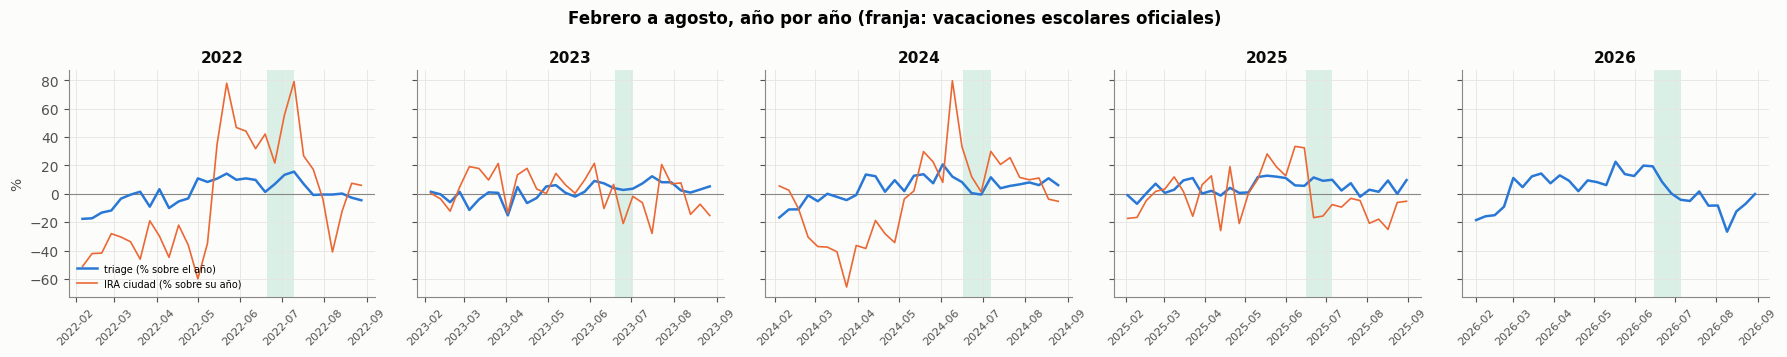

,semanas de vacaciones %,marzo-mayo %
año,,
2022,9.3,2.1
2023,3.5,-1.7
2024,4.9,5.2
2025,9.0,5.2
2026,6.0,10.5
media,6.5,4.3


In [9]:
VAC = {2022: ("2022-06-20", "2022-07-10"), 2023: ("2023-06-19", "2023-07-02"), 2024: ("2024-06-17", "2024-07-07"),
       2025: ("2025-06-16", "2025-07-06"), 2026: ("2026-06-15", "2026-07-05")}   # 2026: sin clases desde el 15-jun
wA = RA.total.resample("W-SAT").mean().rename(lambda i: i - pd.Timedelta(days=6))
wA = wA[RA.total.resample("W-SAT").count().values == 7]
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = inst[inst.cod_upgd.ne(170010010301)].groupby("fecha_inicio_semana")["consultas_ira"].sum()
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
filas = []
for ax, (a, (vi, vf)) in zip(axes, VAC.items()):
    s = pct(wA.loc[f"{a}-02-01":f"{a}-08-31"]); ax.axhline(0, color=MUDO, lw=.8)
    ax.axvspan(pd.Timestamp(vi), pd.Timestamp(vf), color=AQUA, alpha=.15, lw=0)
    ax.plot(s.index, s.values, color=AZUL, lw=1.8, label="triage (% sobre el año)")
    ii = ira.loc[f"{a}-02-01":f"{a}-08-31"]
    if len(ii) > 5:
        ax.plot(ii.index, 100 * (ii / ira.loc[f"{a}"].mean() - 1), color=NARANJA, lw=1.2, label="IRA ciudad (% sobre su año)")
    ax.set_title(str(a)); ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    vac = s[(s.index >= pd.Timestamp(vi) - pd.Timedelta(days=6)) & (s.index <= pd.Timestamp(vf))]
    clase = s[(s.index.month.isin([3, 4, 5])) ]
    filas.append({"año": a, "semanas de vacaciones %": round(vac.mean(), 1), "marzo-mayo %": round(clase.mean(), 1)})
axes[0].set_ylabel("%"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Febrero a agosto, año por año (franja: vacaciones escolares oficiales)", fontweight="bold")
plt.tight_layout(); plt.show()
T5 = pd.DataFrame(filas).set_index("año"); T5.loc["media"] = T5.mean().round(1)
T5


## Lectura

**El propietario tenía razón sobre la mitad de año, y la corrección es de este mismo cuaderno.**
Medido sin descontar las vacaciones (control A: día de la semana, festivo y año):

| Año | Semanas de vacaciones escolares | Marzo-mayo |
|---|---|---|
| 2022 | **+9,3 %** | +2,1 % |
| 2023 | +3,5 % | −1,7 % |
| 2024 | +4,9 % | +5,2 % |
| 2025 | **+9,0 %** | +5,2 % |
| 2026 | +6,0 % | **+10,5 %** |
| **Media** | **+6,5 %** | **+4,3 %** |

- **Las semanas de vacaciones escolares de mitad de año están por encima del nivel del año los
  cinco años**, de +3,5 a +9,3 %. Marzo-mayo también está alto (+4,3 % de media).
- La mitad del año **es la parte alta del año**, de marzo a julio.
- **Esto corrige lo que se dijo antes hoy** (sección 1 y `CONTEXTO.md`, «dos tipos de pico»): que
  el alto caía «en mayo, antes de las vacaciones» y que junio-julio bajaban. Esa lectura salía
  de un control que **ya descontaba** las vacaciones. Medido sin ese descuento, las vacaciones
  son de lo más alto del año.
- **La IRA de la ciudad** (naranja) sube con fuerza de mayo a julio en 2022 y en junio de 2024,
  que es la temporada respiratoria de mitad de año. En 2023 y 2025 es más plana. El triage no
  sigue a la IRA semana a semana (cuaderno 07), pero las dos cosas comparten temporada.

**Límites.**
- **Julio de 2026 cae por el desplome de Nueva EPS**, no por las vacaciones (cuaderno 07,
  sección 5).
- Con cinco años no se puede separar «vacaciones» de «temporada respiratoria» de «fiestas de los
  pueblos de finales de junio»: caen juntas.

---
# 6. Resumen: los picos tienen tres relojes

| Tipo de pico | Cuándo | Qué lo rodea | Reloj | Cómo se anticipa |
|---|---|---|---|---|
| **Noche festiva y día después** | 7-8 dic, 24-26 dic, 31 dic - 4 ene | Riñas (lesiones ×2-3 en la ciudad), alcohol, pólvora, particulares; **madrugada +31 a +44 %** | horas a 3 días | **calendario festivo**, conocido con meses |
| **Arranque de año** | 2-4 ene (+6 a +14 %) | Año Nuevo, regreso de vacaciones, Feria (SOAT +37 %), Carnaval de Riosucio | 0-5 días | calendario, y la huella de la Feria |
| **Temporada de mitad de año** | marzo a julio; vacaciones escolares **+6,5 %** | IRA de la ciudad, vacaciones, fiestas de los pueblos de finales de junio | semanas | nivel de las semanas previas, vigilancia, calendario escolar |
| Fiestas de los pueblos lejanos | junio, agosto, octubre | remisiones probables (CRUE pendiente) | días | calendario de fiestas: **+2 %** |

Y debajo de todo, **el nivel**, que lo mueve la red (Nueva EPS). No es un pico, pero manda sobre
cuánto vale cada pico.

**Lo que esto significa para el modelo:**
1. **El calendario festivo no es solo «es festivo».** Hay que distinguir la noche de fiesta (baja
   de día, sube de madrugada) del día siguiente (sube). Un solo indicador de festivo promedia las
   dos cosas y las borra.
2. **Las vacaciones escolares de mitad de año son una variable propia**, con las fechas oficiales
   de cada año, no las 122 fechas fijas del calendario actual (`03_fuentes_externas`, sección de
   calidad).
3. **Las fiestas de los pueblos entran con peso bajo**, separadas por distancia.
4. **La hora importa.** Parte de los picos está en la madrugada, y un modelo por hora los vería
   donde el diario los diluye.

**Siguiente paso:** fijar estas variables en `patrones/datos/variables.csv` en su forma
definitiva y probarlas **fuera de muestra**, contra el control de calendario, con origen rodante.